### TP1 \- EDA


### INDICE:

### EDA nro 1 \- Exoplanetas \- Federico Suárez
EDA nro 2 \- Estimaciones Agrícolas de Argentina \- Franco Diaz

### Parte 1 

# EXOPLANETAS

### Un exoplaneta es un planeta que gira alrededor de una estrella distinta del Sol\. Este dataset, publicado por la NASA, contiene todos los exoplanetas confirmados hasta noviembre de 2021: unos 4\.500 planetas\.
Cada fila es un planeta, y las columnas cuentan tres cosas sobre él:

### \- Cómo se descubrió: con qué técnica, en qué año y desde qué observatorio\.
\- Cómo es el planeta: cuánto tarda en dar una vuelta a su estrella, qué tan lejos está de ella, cuánto pesa, qué temperatura tiene\.
\- Cómo es su estrella: qué tan caliente y grande es, y a qué distancia está de nosotros\.

### El objetivo de este análisis es conocer el dataset: qué información tiene, qué le falta, cómo se reparten los valores y qué variables se relacionan entre sí\.

## 1\. Cargar los datos\.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("all_exoplanets_2021.csv")
df.shape

FileNotFoundError: [Errno 2] No such file or directory: 'all_exoplanets_2021.csv'

### Ver las primeras 5 filas para entender cómo vienen los datos\.

In [5]:
df.head()

,No.,Planet Name,Planet Host,Num Stars,Num Planets,Discovery Method,Discovery Year,Discovery Facility,Orbital Period Days,Orbit Semi-Major Axis,...,Equilibrium Temperature,Spectral Type,Stellar Effective Temperature,Stellar Radius,Stellar Mass,Stellar Metallicity,Stellar Metallicity Ratio,Stellar Surface Gravity,Distance,Gaia Magnitude
0,1,11 Com b,11 Com,2,1,Radial Velocity,2007,Xinglong Station,326.03000,1.29,...,NaN,G8 III,4742.0,19.00,2.70,-0.35,[Fe/H],2.31,93.1846,4.44038
1,2,11 UMi b,11 UMi,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,516.21997,1.53,...,NaN,NaN,4213.0,29.79,2.78,-0.02,[Fe/H],1.93,125.3210,4.56216
2,3,14 And b,14 And,1,1,Radial Velocity,2008,Okayama Astrophysical Observatory,185.84000,0.83,...,NaN,K0 III,4813.0,11.00,2.20,-0.24,[Fe/H],2.63,75.4392,4.91781
3,4,14 Her b,14 Her,1,2,Radial Velocity,2002,W. M. Keck Observatory,1773.40002,2.93,...,NaN,NaN,5338.0,0.93,0.90,0.41,[Fe/H],4.45,17.9323,6.38300
4,5,16 Cyg B b,16 Cyg B,3,1,Radial Velocity,1996,Multiple Observatories,798.50000,1.66,...,NaN,NaN,5750.0,1.13,1.08,0.06,[Fe/H],4.36,21.1397,6.06428


### Ver el tipo de dato de cada columna y cuántos valores tiene cargados cada una\.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4575 entries, 0 to 4574
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   No.                            4575 non-null   int64  
 1   Planet Name                    4575 non-null   object 
 2   Planet Host                    4575 non-null   object 
 3   Num Stars                      4575 non-null   int64  
 4   Num Planets                    4575 non-null   int64  
 5   Discovery Method               4575 non-null   object 
 6   Discovery Year                 4575 non-null   int64  
 7   Discovery Facility             4575 non-null   object 
 8   Orbital Period Days            4413 non-null   float64
 9   Orbit Semi-Major Axis          2763 non-null   float64
 10  Mass                           2006 non-null   float64
 11  Eccentricity                   1707 non-null   float64
 12  Insolation Flux                370 non-null    f

### Extracción de la columna "No\.", es solo un número de fila\. Y pasamos los nombres de columnas a minúsculas con guiones bajos, para que sea más fácil escribirlos en el código\.

In [5]:
df = df.drop(columns=["No."])
df.columns = df.columns.str.lower().str.replace(" ", "_").str.replace("-", "_")
df.columns.tolist()

['planet_name',
 'planet_host',
 'num_stars',
 'num_planets',
 'discovery_method',
 'discovery_year',
 'discovery_facility',
 'orbital_period_days',
 'orbit_semi_major_axis',
 'mass',
 'eccentricity',
 'insolation_flux',
 'equilibrium_temperature',
 'spectral_type',
 'stellar_effective_temperature',
 'stellar_radius',
 'stellar_mass',
 'stellar_metallicity',
 'stellar_metallicity_ratio',
 'stellar_surface_gravity',
 'distance',
 'gaia_magnitude']

### Resumen estadístico de las columnas numéricas: promedio, mínimo, máximo, mediana, etc\. Sirve para tener una primera idea de en qué rango se mueve cada variable\.

In [7]:
df.describe().round(2)

,num_stars,num_planets,discovery_year,orbital_period_days,orbit_semi_major_axis,mass,eccentricity,insolation_flux,equilibrium_temperature,stellar_effective_temperature,stellar_radius,stellar_mass,stellar_metallicity,stellar_surface_gravity,distance,gaia_magnitude
count,4575.00,4575.00,4575.00,4.413000e+03,2763.00,2006.00,1707.00,370.00,925.00,4226.00,4128.00,3844.00,3204.00,3972.00,4471.00,4400.00
mean,1.11,1.79,2014.86,9.489932e+04,10.94,725.12,0.15,446.66,1057.81,5439.17,1.54,0.97,0.01,4.36,656.38,12.43
std,0.35,1.17,3.96,6.053595e+06,182.40,1338.02,0.18,2456.28,561.19,1420.27,3.82,0.47,0.18,0.43,938.41,2.99
min,1.00,1.00,1989.00,9.000000e-02,0.00,0.02,0.00,0.06,50.00,575.00,0.01,0.01,-1.00,1.20,1.30,2.93
25%,1.00,1.00,2014.00,4.440000e+00,0.06,16.15,0.01,5.71,619.00,4989.25,0.79,0.79,-0.07,4.29,123.74,10.75
50%,1.00,1.00,2016.00,1.176000e+01,0.12,220.89,0.09,45.70,961.00,5574.00,0.96,0.96,0.02,4.45,434.75,13.36
75%,1.00,2.00,2016.00,4.101000e+01,0.68,740.54,0.22,226.52,1457.00,5908.00,1.25,1.11,0.11,4.56,856.42,14.78
max,4.00,8.00,2021.00,4.020000e+08,7506.00,17668.17,0.95,44900.00,4050.00,40000.00,83.80,10.94,0.55,7.92,8200.00,20.19


## 2\. Calidad de los datos

### Valores Faltantes\. Muchas columnas tienen celdas vacías\. Calculamos qué porcentaje de cada columna está vacío\.

In [9]:
faltantes = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
faltantes

insolation_flux                  91.9
equilibrium_temperature          79.8
spectral_type                    79.7
eccentricity                     62.7
mass                             56.2
orbit_semi_major_axis            39.6
stellar_metallicity_ratio        30.2
stellar_metallicity              30.0
stellar_mass                     16.0
stellar_surface_gravity          13.2
stellar_radius                    9.8
stellar_effective_temperature     7.6
gaia_magnitude                    3.8
orbital_period_days               3.5
distance                          2.3
discovery_method                  0.0
discovery_year                    0.0
num_stars                         0.0
planet_host                       0.0
planet_name                       0.0
num_planets                       0.0
discovery_facility                0.0
dtype: float64

### Gráfico de barras para que se note más claro qué columnas están más incompletas\. Las que tienen más faltantes son medidas que no siempre se pueden obtener cuando se descubre un planeta \(por ejemplo, la temperatura del planeta\), por eso están vacías en muchos casos\.

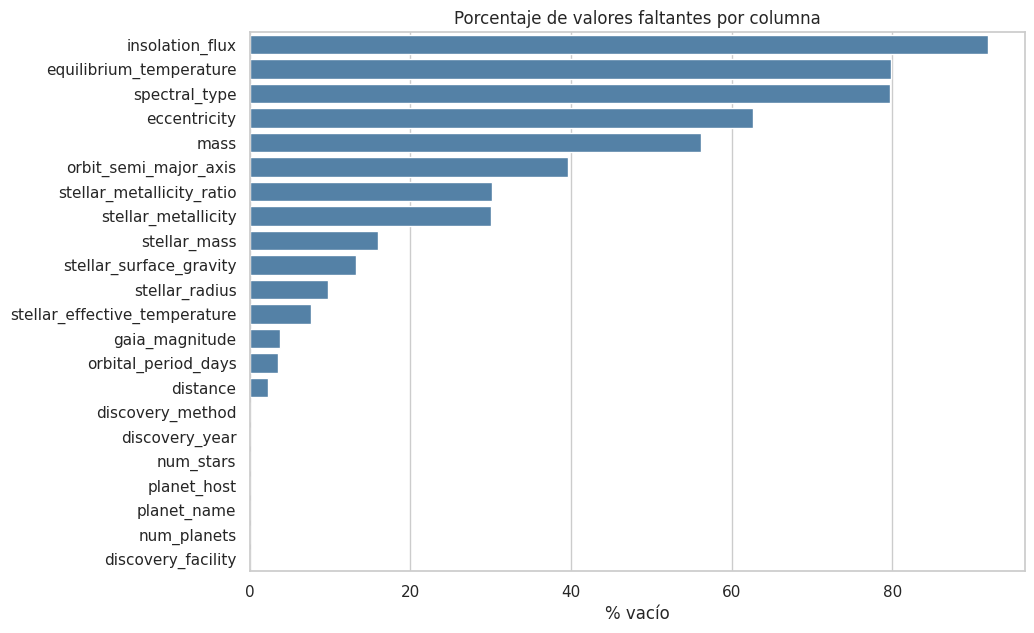

In [11]:
plt.figure(figsize=(10, 7))
sns.barplot(x=faltantes.values, y=faltantes.index, color="steelblue")
plt.title("Porcentaje de valores faltantes por columna")
plt.xlabel("% vacío")
plt.ylabel("")
plt.show()

### Filas repetidas\. Chequeo de que no haya filas duplicadas y que no haya dos planetas con el mismo nombre\.

In [13]:
print("Filas duplicadas:", df.duplicated().sum())
print("Nombres repetidos:", df["planet_name"].duplicated().sum())

Filas duplicadas: 0
Nombres repetidos: 0


## 3\. Cómo y cuándo se descubrieron estos exoplanetas\.

### Método de descubrimiento

### Hay distintas técnicas para encontrar un planeta\. Contamos cuántos planetas se encontraron con cada una\.

In [15]:
df["discovery_method"].value_counts()

discovery_method
Transit                          3444
Radial Velocity                   899
Microlensing                      120
Imaging                            54
Transit Timing Variations          22
Eclipse Timing Variations          16
Orbital Brightness Modulation       9
Pulsar Timing                       7
Pulsation Timing Variations         2
Disk Kinematics                     1
Astrometry                          1
Name: count, dtype: int64

### Gráfico\. Se ve que dos técnicas dominan claramente: Transit \(se detecta una pequeña baja en el brillo de la estrella cuando el planeta pasa por delante\) y Radial Velocity \(se detecta un pequeño "tambaleo" de la estrella provocado por el planeta\)\.

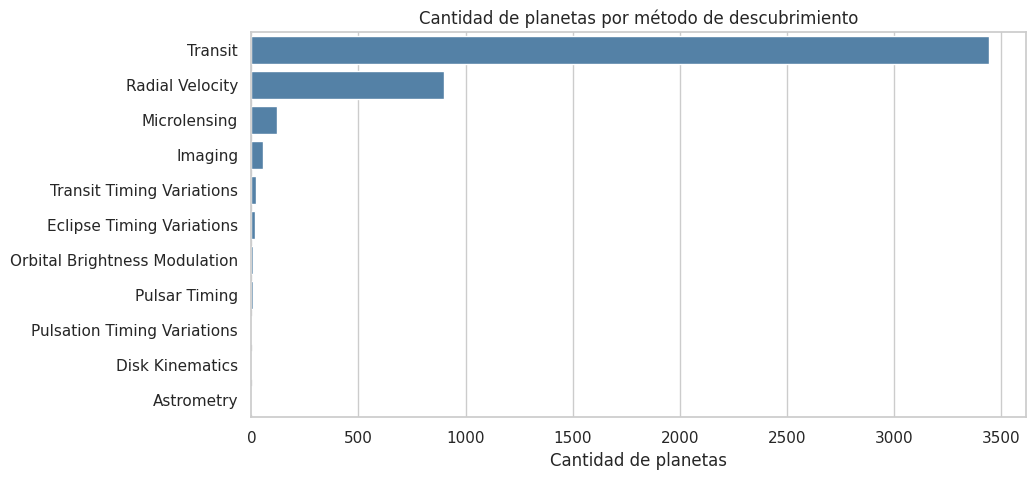

In [17]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="discovery_method", order=df["discovery_method"].value_counts().index, color="steelblue")
plt.title("Cantidad de planetas por método de descubrimiento")
plt.xlabel("Cantidad de planetas")
plt.ylabel("")
plt.show()

### Año de descubrimiento

### Cuántos planetas se descubrieron cada año\. Se ven años con picos muy altos, que corresponden a momentos en que un telescopio publicó muchos descubrimientos juntos\.

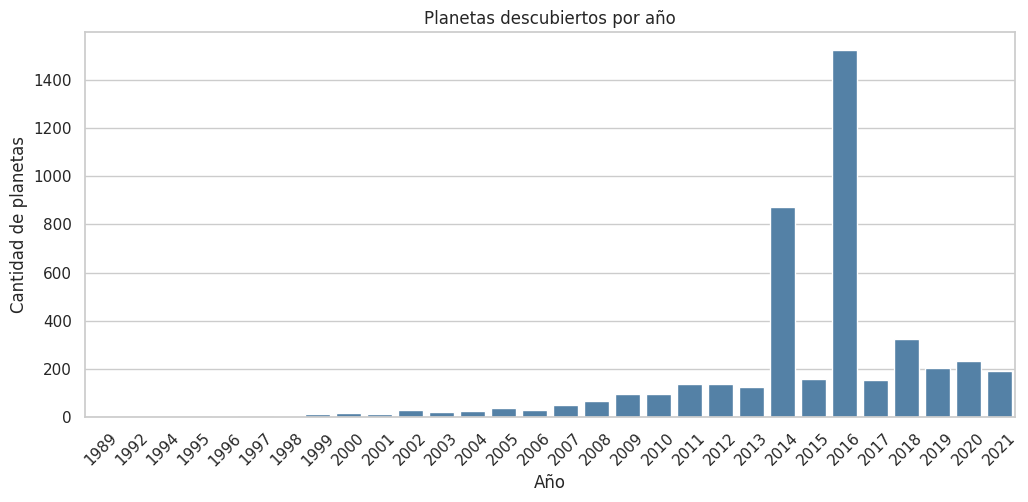

In [19]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="discovery_year", color="steelblue")
plt.title("Planetas descubiertos por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de planetas")
plt.xticks(rotation=45)
plt.show()

### Observatorio

### Hay muchos observatorios distintos, así que mostramos solo los 10 que más planetas descubrieron\.

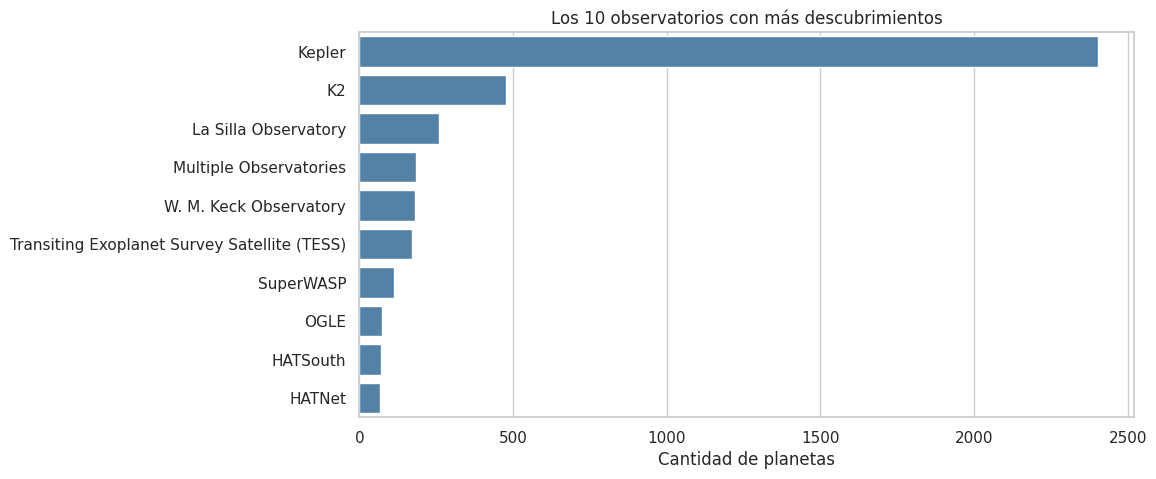

In [21]:
top_obs = df["discovery_facility"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_obs.values, y=top_obs.index, color="steelblue")
plt.title("Los 10 observatorios con más descubrimientos")
plt.xlabel("Cantidad de planetas")
plt.ylabel("")
plt.show()

## 4\. ¿Cómo son los planetas?

### Cuántos planetas tiene cada sistema

### "num\_planets" indica cuántos planetas se conocen en el sistema al que pertenece cada fila\. La mayoría de los sistemas tiene un solo planeta conocido\.

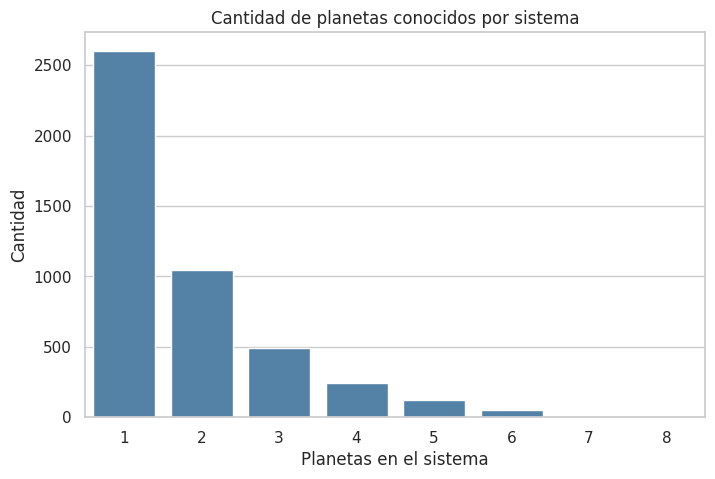

In [23]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="num_planets", color="steelblue")
plt.title("Cantidad de planetas conocidos por sistema")
plt.xlabel("Planetas en el sistema")
plt.ylabel("Cantidad")
plt.show()

### Período orbital

### El período orbital es cuánto tarda el planeta en dar una vuelta completa a su estrella, en días \(la Tierra tarda 365\)\. Hay planetas que tardan menos de un día y otros que tardan miles de días, así que si graficamos directo casi todo queda apretado a la izquierda\. Por eso usamos escala logarítmica en el eje X, que estira los valores chicos y comprime los grandes\.

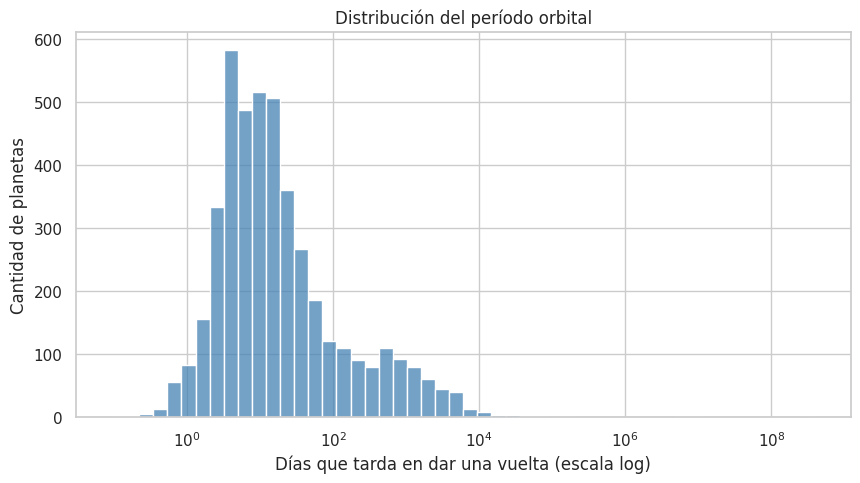

In [25]:
plt.figure(figsize=(10, 5))
sns.histplot(df["orbital_period_days"].dropna(), bins=50, log_scale=True, color="steelblue")
plt.title("Distribución del período orbital")
plt.xlabel("Días que tarda en dar una vuelta (escala log)")
plt.ylabel("Cantidad de planetas")
plt.show()

### Masa

### La masa está medida en "masas terrestres": un valor de 1 significa que pesa lo mismo que la Tierra, 318 sería como Júpiter\. Igual que antes, usamos escala logarítmica\.

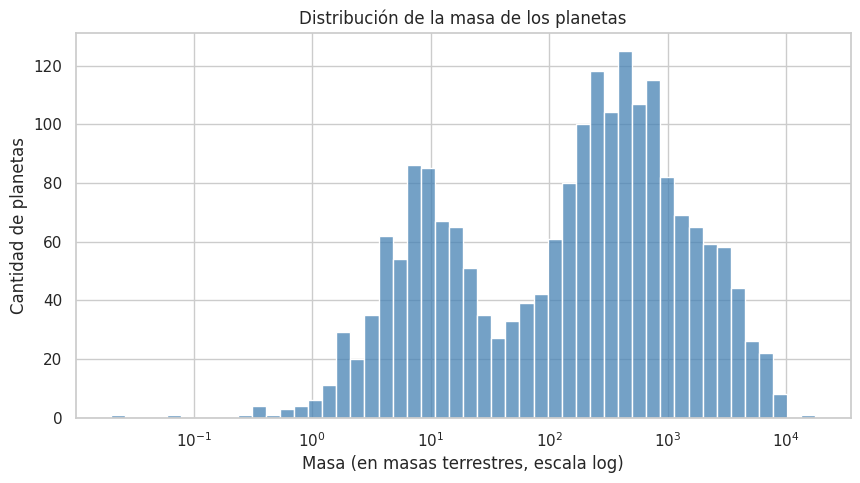

In [27]:
plt.figure(figsize=(10, 5))
sns.histplot(df["mass"].dropna(), bins=50, log_scale=True, color="steelblue")
plt.title("Distribución de la masa de los planetas")
plt.xlabel("Masa (en masas terrestres, escala log)")
plt.ylabel("Cantidad de planetas")
plt.show()

### Temperatura

### La temperatura de equilibrio es una estimación de qué tan caliente está el planeta, en grados Kelvin \(la Tierra ronda los 255 K\)\. Esta variable sí se puede ver en escala normal\.

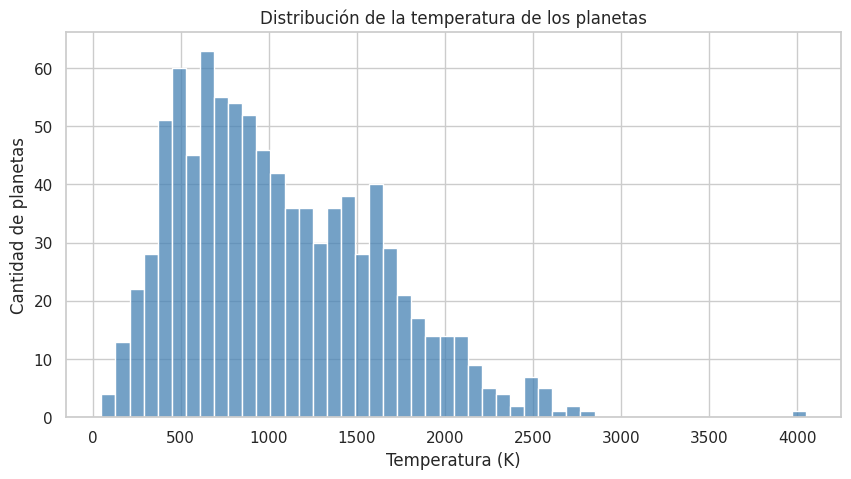

In [29]:
plt.figure(figsize=(10, 5))
sns.histplot(df["equilibrium_temperature"].dropna(), bins=50, color="steelblue")
plt.title("Distribución de la temperatura de los planetas")
plt.xlabel("Temperatura (K)")
plt.ylabel("Cantidad de planetas")
plt.show()

### Distancia a la Tierra

### Qué tan lejos está el sistema, en parsecs \(1 parsec = 3,26 años luz\)\. Escala logarítmica de nuevo, porque hay sistemas muy cercanos y otros lejísimos\.

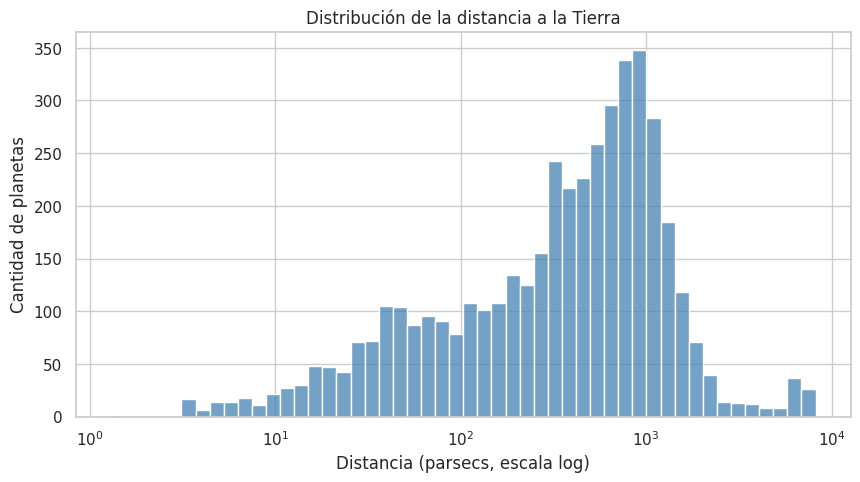

In [31]:
plt.figure(figsize=(10, 5))
sns.histplot(df["distance"].dropna(), bins=50, log_scale=True, color="steelblue")
plt.title("Distribución de la distancia a la Tierra")
plt.xlabel("Distancia (parsecs, escala log)")
plt.ylabel("Cantidad de planetas")
plt.show()

### Valores extremos

### Un boxplot muestra dónde está la mayoría de los datos \(la caja\) y cuáles son los valores raros \(los puntos sueltos\)\. En este dataset los valores extremos suelen ser planetas reales pero poco comunes \(muy grandes o con órbitas muy largas\), no errores de carga, así que no se eliminan\.

/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


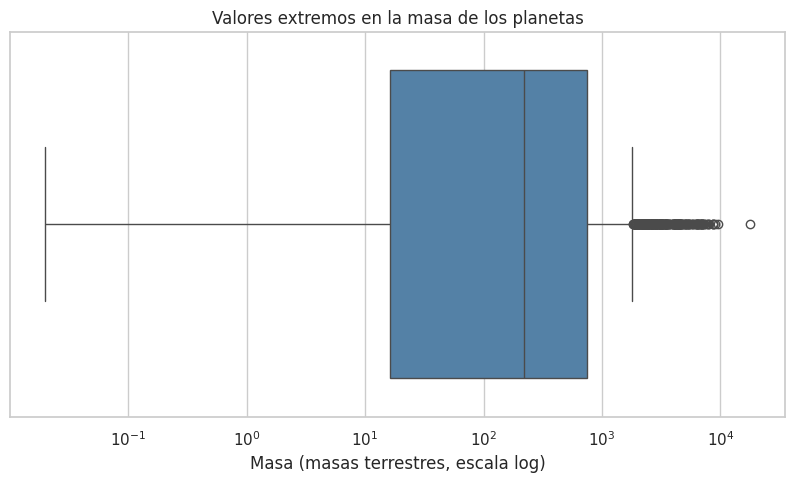

In [33]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["mass"].dropna(), color="steelblue")
plt.xscale("log")
plt.title("Valores extremos en la masa de los planetas")
plt.xlabel("Masa (masas terrestres, escala log)")
plt.show()

## 5\. ¿Cómo son las estrellas?

### Temperatura de la estrella

### Temperatura de la superficie de la estrella, en Kelvin\. El Sol tiene unos 5\.800 K\. Se ve que la mayoría de las estrellas del dataset son parecidas al Sol o un poco más frías\.

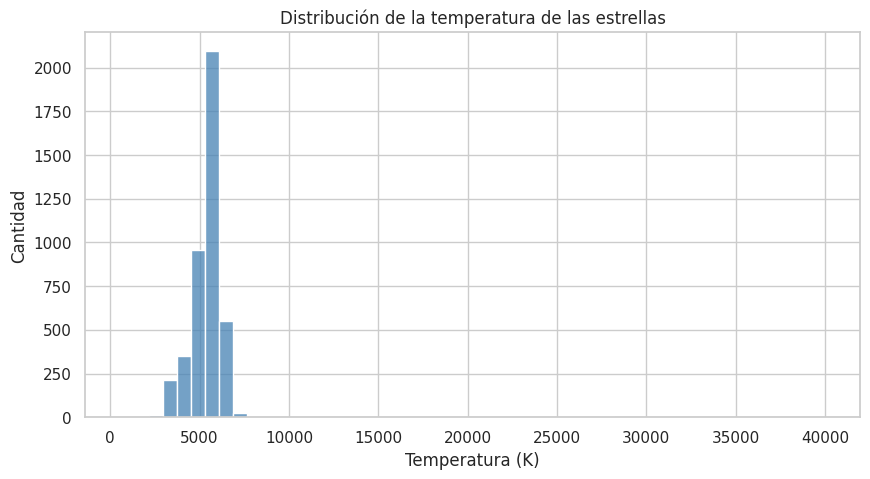

In [35]:
plt.figure(figsize=(10, 5))
sns.histplot(df["stellar_effective_temperature"].dropna(), bins=50, color="steelblue")
plt.title("Distribución de la temperatura de las estrellas")
plt.xlabel("Temperatura (K)")
plt.ylabel("Cantidad")
plt.show()

### Masa de la estrella

### Medida en "masas solares": 1 significa que pesa lo mismo que el Sol\.

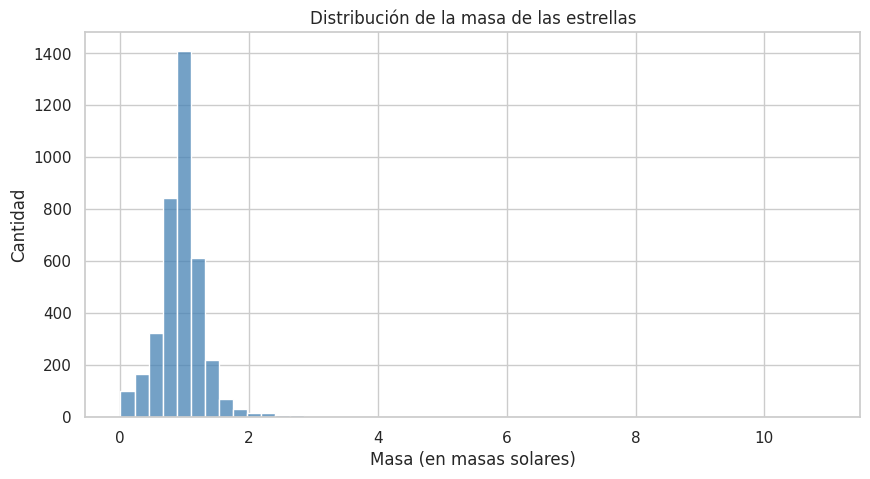

In [37]:
plt.figure(figsize=(10, 5))
sns.histplot(df["stellar_mass"].dropna(), bins=50, color="steelblue")
plt.title("Distribución de la masa de las estrellas")
plt.xlabel("Masa (en masas solares)")
plt.ylabel("Cantidad")
plt.show()

## 6\. ¿Qué variables se relacionan entre sí?

### Matriz de correlación

### La correlación mide si dos variables suben y bajan juntas\. Va de \-1 a 1: cerca de 1 significa que cuando una crece la otra también, cerca de \-1 que cuando una crece la otra baja, y cerca de 0 que no tienen relación\. Elegimos las variables más importantes para que el gráfico se lea bien\.

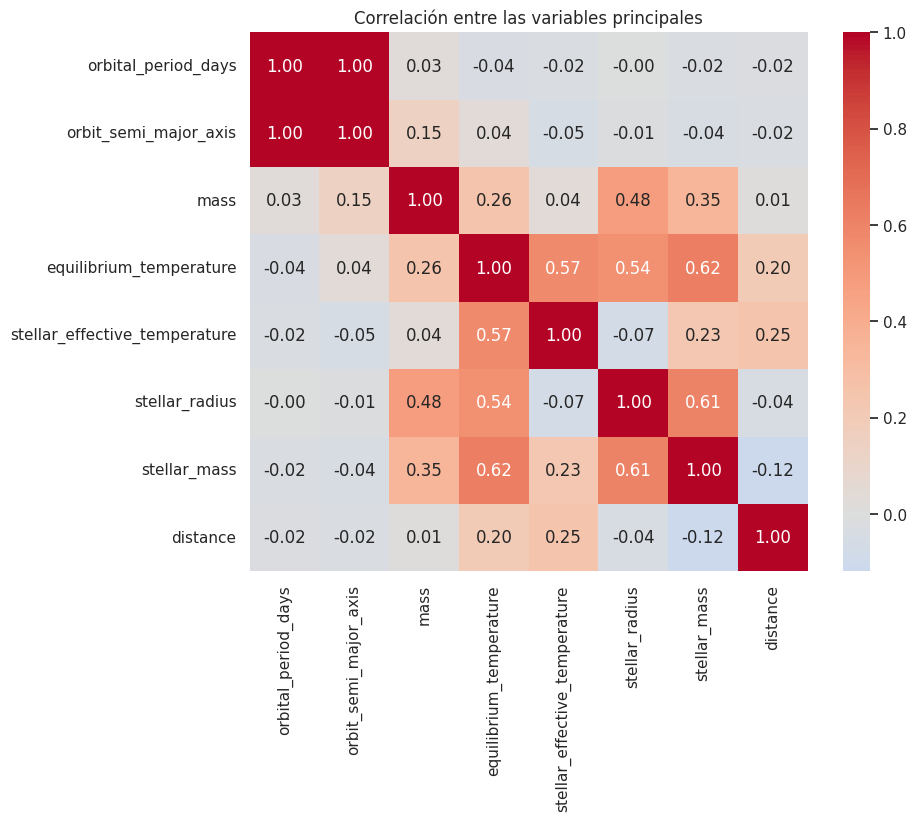

In [39]:
cols = ["orbital_period_days", "orbit_semi_major_axis", "mass", "equilibrium_temperature",
        "stellar_effective_temperature", "stellar_radius", "stellar_mass", "distance"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre las variables principales")
plt.show()

### Distancia a la estrella vs período orbital

### Es lógico pensar que cuanto más lejos está un planeta de su estrella, más tarda en dar la vuelta\. El gráfico lo confirma: los puntos forman casi una línea\. Ambos ejes en escala logarítmica\.

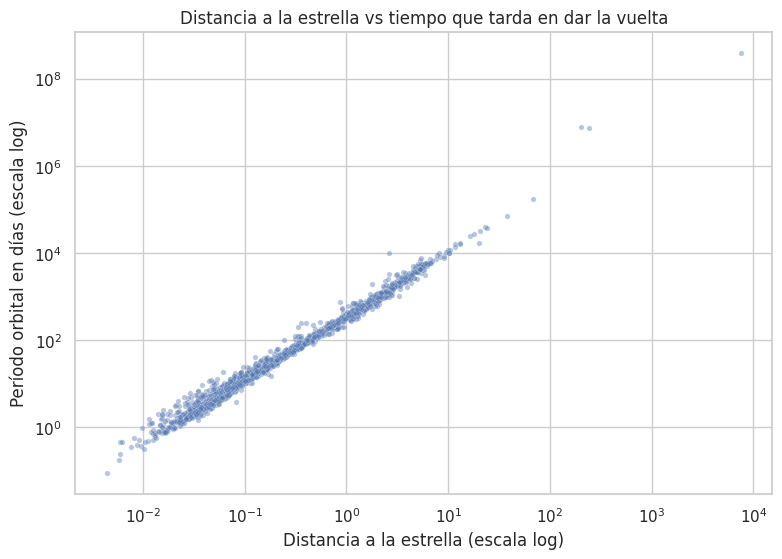

In [41]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="orbit_semi_major_axis", y="orbital_period_days", alpha=0.4, s=15)
plt.xscale("log")
plt.yscale("log")
plt.title("Distancia a la estrella vs tiempo que tarda en dar la vuelta")
plt.xlabel("Distancia a la estrella (escala log)")
plt.ylabel("Período orbital en días (escala log)")
plt.show()

### Distancia a la estrella vs temperatura

### Cuanto más cerca de la estrella, más caliente el planeta\. Se ve la relación inversa: a mayor distancia, menor temperatura\.

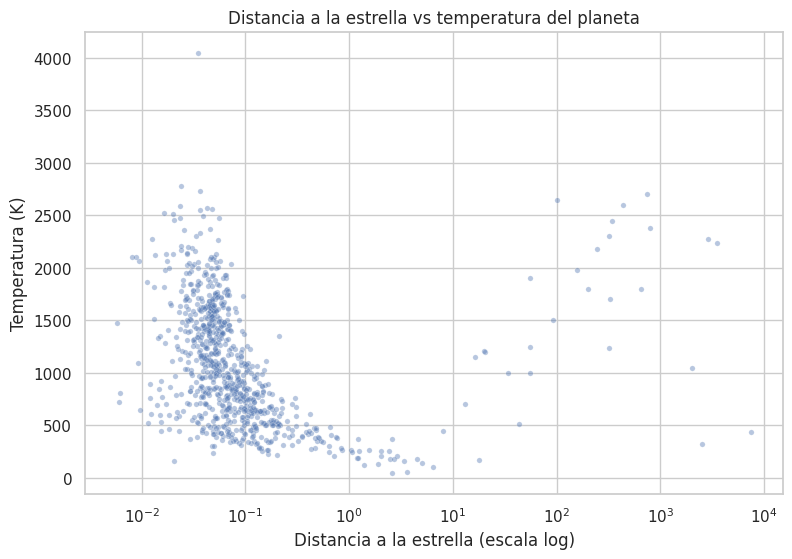

In [43]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="orbit_semi_major_axis", y="equilibrium_temperature", alpha=0.4, s=15)
plt.xscale("log")
plt.title("Distancia a la estrella vs temperatura del planeta")
plt.xlabel("Distancia a la estrella (escala log)")
plt.ylabel("Temperatura (K)")
plt.show()

## 7\. ¿Cada método encuentra planetas distintos?

### Para simplificar, nos quedamos con los dos métodos principales y agrupamos el resto como "Otros"\.

In [45]:
principales = ["Transit", "Radial Velocity"]
df["metodo"] = np.where(df["discovery_method"].isin(principales), df["discovery_method"], "Otros")
df["metodo"].value_counts()

metodo
Transit            3444
Radial Velocity     899
Otros               232
Name: count, dtype: int64

### Comparamos la masa de los planetas según el método con que se descubrieron\. Se ve que Radial Velocity tiende a encontrar planetas más pesados que Transit\.

/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


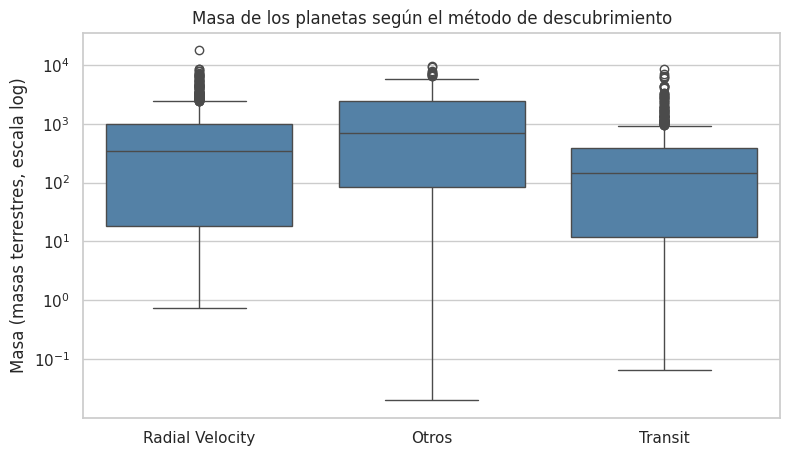

In [47]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="metodo", y="mass", color="steelblue")
plt.yscale("log")
plt.title("Masa de los planetas según el método de descubrimiento")
plt.xlabel("")
plt.ylabel("Masa (masas terrestres, escala log)")
plt.show()

### Lo mismo con el período orbital\. Transit encuentra sobre todo planetas que dan la vuelta rápido \(están muy cerca de su estrella\)\.

/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


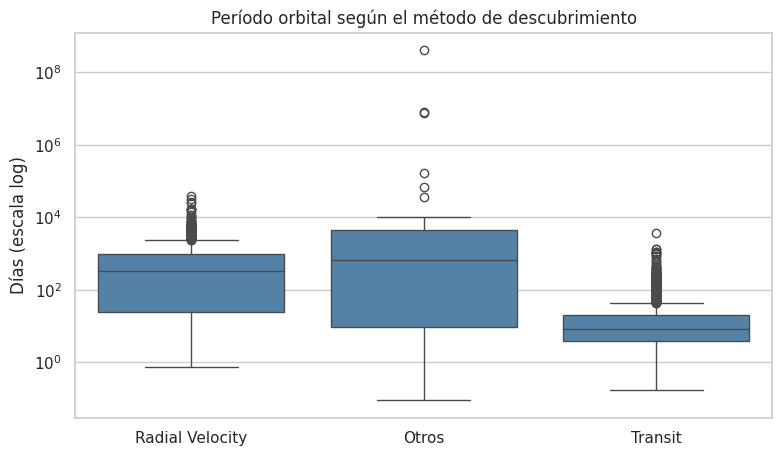

In [49]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="metodo", y="orbital_period_days", color="steelblue")
plt.yscale("log")
plt.title("Período orbital según el método de descubrimiento")
plt.xlabel("")
plt.ylabel("Días (escala log)")
plt.show()

### Resumen en una tabla: la mediana \(el valor "del medio"\) de masa, período y distancia para cada método\.

In [51]:
df.groupby("metodo")[["mass", "orbital_period_days", "distance"]].median().round(1)

,mass,orbital_period_days,distance
metodo,,,
Otros,700.0,675.5,2220.0
Radial Velocity,344.0,326.0,42.5
Transit,144.6,8.6,573.6


## 8\. Conclusiones

### \- El dataset tiene unos 4\.500 planetas y 22 columnas útiles, con información sobre el descubrimiento, el planeta y su estrella\.

### 
\- Varias columnas tienen muchos valores vacíos \(temperatura, flujo, tipo de estrella\), porque no siempre se pueden medir\. Si más adelante se quiere hacer un modelo, habría que decidir si esas columnas se descartan o se completan\.

### 
\- Casi todos los planetas se descubrieron con dos técnicas: Transit y Radial Velocity\. Hay años con muchos descubrimientos juntos por telescopios espaciales\.

### 
\- Muchas variables \(período, masa, distancia\) tienen valores que van de muy chicos a enormes, por eso hay que graficarlas en escala logarítmica para poder verlas bien\.

### 
\- Las relaciones más claras son de sentido común: a mayor distancia de la estrella, más tarda en dar la vuelta y más frío es el planeta\.

### 
\- Cada técnica encuentra planetas distintos: Transit encuentra planetas cercanos a su estrella y Radial Velocity encuentra planetas pesados\. Esto quiere decir que el dataset no muestra "cómo son los planetas en general" sino "cuáles somos capaces de encontrar"\.

### 
\- Los valores extremos son planetas reales pero raros, no errores, así que no se eliminaron\.


# Parte 2 \- Estimaciones Agrícolas de Argentina \- Franco Diaz

# TP1 EDA

Franco Diaz

Dataset: Estimaciones Agrícolas de Argentina

Descripción: El conjunto de datos contiene información agrícola histórica relacionada con cultivos, campañas, provincias, departamentos, superficie sembrada, superficie cosechada, producción y rendimiento\.

Carga del dataset y de las librerias necesarias para el EDA

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("estimaciones-agricolas-2026-03 (1).csv")
df

,cultivo,anio,campania,provincia,provincia_id,departamento,departamento_id,superficie_sembrada_ha,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha
0,ajo,1969,1969/1970,Buenos Aires,6.0,25 de Mayo,6854.0,3,3,10,3333
1,ajo,1969,1969/1970,Buenos Aires,6.0,Adolfo Gonzales Chaves,6014.0,15,15,82,5467
2,ajo,1969,1969/1970,Buenos Aires,6.0,Almirante Brown,6028.0,2,2,8,4000
3,ajo,1969,1969/1970,Buenos Aires,6.0,Balcarce,6063.0,450,450,2025,4500
4,ajo,1969,1969/1970,Buenos Aires,6.0,Cañuelas,6134.0,2,2,7,3500
...,...,...,...,...,...,...,...,...,...,...,...
160494,yerba mate,2024,2023/2024,Misiones,54.0,Apóstoles,54007.0,18197,16843,76635,4550
160495,yerba mate,2024,2023/2024,Misiones,54.0,Cainguás,54014.0,21264,19814,89161,4500
160496,yerba mate,2024,2023/2024,Misiones,54.0,San Ignacio,54098.0,18933,17826,83784,4700
160497,yerba mate,2024,2023/2024,Misiones,54.0,Oberá,54091.0,25327,24199,113738,4700


Dimensiones del Dataset

El conjunto de datos contiene 160\.499 filas y 11 columnas\.

In [5]:
df.shape

(160499, 11)

 Información General

Se analizaron los tipos de datos presentes en el dataset\.

Se observan variables categóricas como cultivo, campaña y provincia, además de variables numéricas relacionadas con superficie, producción y rendimiento\.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160499 entries, 0 to 160498
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   cultivo                  160499 non-null  object 
 1   anio                     160499 non-null  int64  
 2   campania                 160499 non-null  object 
 3   provincia                160491 non-null  object 
 4   provincia_id             160491 non-null  float64
 5   departamento             160491 non-null  object 
 6   departamento_id          160491 non-null  float64
 7   superficie_sembrada_ha   160499 non-null  int64  
 8   superficie_cosechada_ha  160499 non-null  int64  
 9   produccion_tm            160499 non-null  int64  
 10  rendimiento_kgxha        160499 non-null  int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 13.5+ MB


Vista inicial

Se visualizan las primeras filas para conocer la estructura general del conjunto de datos\.

In [4]:
df.head()

,cultivo,anio,campania,provincia,provincia_id,departamento,departamento_id,superficie_sembrada_ha,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha
0,ajo,1969,1969/1970,Buenos Aires,6.0,25 de Mayo,6854.0,3,3,10,3333
1,ajo,1969,1969/1970,Buenos Aires,6.0,Adolfo Gonzales Chaves,6014.0,15,15,82,5467
2,ajo,1969,1969/1970,Buenos Aires,6.0,Almirante Brown,6028.0,2,2,8,4000
3,ajo,1969,1969/1970,Buenos Aires,6.0,Balcarce,6063.0,450,450,2025,4500
4,ajo,1969,1969/1970,Buenos Aires,6.0,Cañuelas,6134.0,2,2,7,3500


Estadísticas descriptivas

Las estadísticas descriptivas permiten observar medidas como media, mínimo, máximo y percentiles para las variables numéricas\.

In [5]:
df.describe()

,anio,provincia_id,departamento_id,superficie_sembrada_ha,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha
count,160499.000000,160491.000000,160491.000000,160499.000000,160499.000000,1.604990e+05,160499.000000
mean,1993.494283,33.962789,34156.046576,12565.279547,11022.879538,3.438599e+04,3457.047483
std,17.077850,29.476006,29358.694901,36260.604218,34774.169647,1.300616e+05,5475.852516
min,1969.000000,6.000000,6000.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,1978.000000,6.000000,6672.000000,200.000000,74.000000,1.970000e+02,1000.000000
50%,1990.000000,22.000000,22070.000000,1500.000000,800.000000,1.820000e+03,2000.000000
75%,2009.000000,58.000000,58007.000000,9000.000000,6275.000000,1.480000e+04,3500.000000
max,2024.000000,94.000000,94000.000000,894613.000000,883613.000000,8.620000e+06,300000.000000


Valores Faltantes

Se verifica la existencia de valores nulos dentro del dataset\.

In [6]:
df.isnull().sum()

cultivo                    0
anio                       0
campania                   0
provincia                  8
provincia_id               8
departamento               8
departamento_id            8
superficie_sembrada_ha     0
superficie_cosechada_ha    0
produccion_tm              0
rendimiento_kgxha          0
dtype: int64

Analisis de Cultivos

Se identifican los cultivos presentes en el conjunto de datos y su frecuencia\.

In [7]:
df["cultivo"].value_counts()

cultivo
maíz                17725
trigo total         13292
sorgo               12135
soja total          11983
avena               11534
girasol             10647
cebada forrajera     6572
soja 1ra             6474
centeno              6045
papa total           5628
soja 2da             5111
cebada cervecera     4425
cebolla total        4410
algodón              4350
ajo                  4097
lino                 3991
naranja              3035
poroto total         2785
mijo                 2662
mandarina            2490
alpiste              2248
limón                2226
arroz                2081
maní                 2032
pomelo               2003
colza                1600
cebada total         1364
caña de azúcar       1299
trigo candeal        1245
yerba mate           1012
té                    989
tung                  681
arveja                527
cártamo               500
banana                431
garbanzo              305
poroto negro          182
poroto otros          155
lent

Grafico

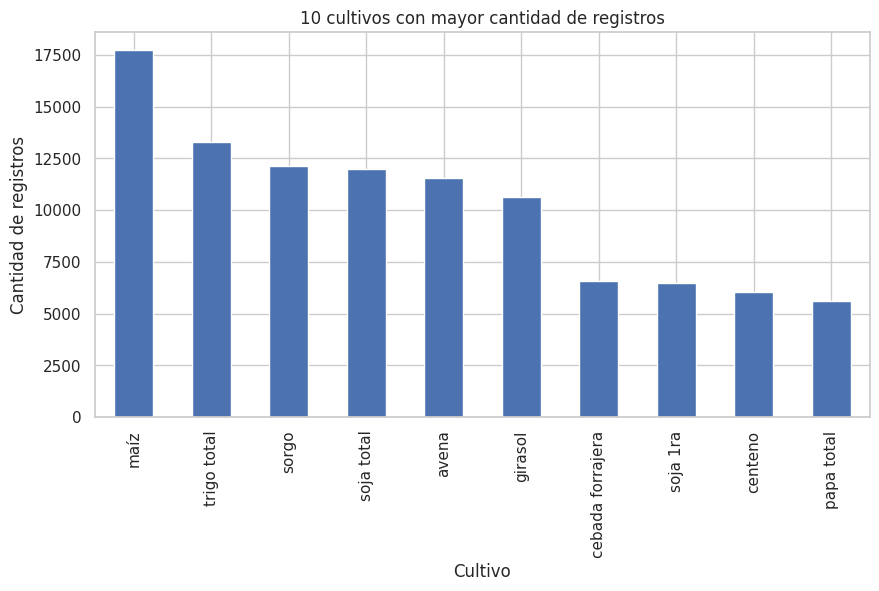

In [9]:
df["cultivo"].value_counts().head(10).plot(kind="bar", figsize=(10,5))

plt.title("10 cultivos con mayor cantidad de registros")
plt.xlabel("Cultivo")
plt.ylabel("Cantidad de registros")

plt.show()

Provincias

In [9]:
df["provincia"].value_counts().head(10)

provincia
Buenos Aires           53317
Santa Fe               12168
Córdoba                11727
Chaco                   9606
Entre Ríos              8823
La Pampa                8589
Corrientes              8320
Misiones                7672
Santiago del Estero     7614
Salta                   6649
Name: count, dtype: int64

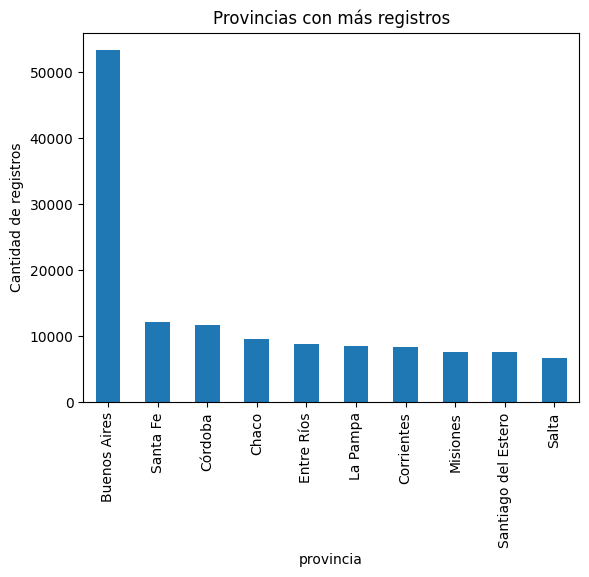

In [10]:
df["provincia"].value_counts().head(10).plot(kind="bar")
plt.ylabel("Cantidad de registros")
plt.title("Provincias con más registros")
plt.show()

Conclusion:

El dataset seleccionado contiene una gran cantidad de registros y variables relacionadas con la producción agrícola argentina\. Durante el análisis exploratorio se identificaron distintas categorías de cultivos y una amplia cobertura territorial por provincias y departamentos\. La información disponible resulta adecuada para realizar análisis posteriores vinculados a producción agrícola, rendimiento y evolución de cultivos, por lo que constituye una buena base\.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=f91bfa8f-f4dc-4813-904a-6c7fc26eb726' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>